# Engines: ignite

> bonsai training engines: ignite/monai backend


In [1]:
#| default_exp engines.ignite

In [2]:
#| hide
from nbdev.showdoc import *
from fastcore.test import *

from bonsai.datasets import download_medmnist
from bonsai.optimizers import Adam

In [3]:
#| export

# =================================
# Standard library
# =================================

from __future__ import annotations

import inspect
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from typing import TYPE_CHECKING, Any, Callable, Dict, Mapping, Optional, Type
from pathlib import Path

# =================================
# Scientific / data
# =================================
import numpy as np
import pandas as pd

# =================================
# Visualization
# =================================
import matplotlib.pyplot as plt
plt.ion()
from matplotlib.colors import LinearSegmentedColormap

from contextlib import contextmanager

# =================================
# Imaging
# =================================
# from skimage import util

# =================================
# PyTorch
# =================================
import torch
import torch.optim as toptim
from torch.optim import Optimizer
from torch.cuda import is_available as is_cuda_available
from torch.nn.init import kaiming_normal_

# =================================
# MONAI
# =================================
from monai.engines.utils import (default_make_latent,
                                 default_metric_cmp_fn,
                                 default_prepare_batch
                                 )
from monai.handlers.utils import from_engine
from monai.handlers import IgniteMetricHandler
from monai.metrics import LossMetric
from monai.utils.enums import ForwardMode

# =================================
# fastai
# =================================
from fastai.callback.core import Callback
from fastai.callback.all import *

from fastai.data.all import (
    DataLoaders, Path, trainable_params, delegates,
    hasattrs, List, L, Normalize
)

from fastai.optimizer import OptimWrapper, Optimizer as fastaiOptimizer

from fastai.vision.all import (
    Any, BypassNewMeta, ClassificationInterpretation,
    DataBlock, DisplayedTransform, Learner,
    create_vision_model, create_timm_model, default_split,
    get_c, ifnone, minimum, model_meta, slide, steep, store_attr, valley
)

# =================================
# fastcore
# =================================
from fastcore.script import risinstance

# =================================
# bonsai
# =================================
from bonsai.backend import get_backend
from bonsai.optimizers import Adam
from bonsai.utils import *
from bonsai.callbacks import CSVLogger, MeanLossGraphCallback
from bonsai.visualize import teal_cmap
from bonsai.engines.core import *
from bonsai.engines.core import (_evaluation_metrics, _prediction_activation, _evaluation_detach, _monai_metric_config,
                                 _display_evaluation_statistics, _prediction_decode, _metric_prediction, _display_evaluation_outputs)

In [4]:
#| export

def _monai_build_evaluator(self):
    """
    Build the evaluator selected by ``config.trainer``.

    Returns
    -------
    Any
        The constructed evaluator.
    """
    backend_trainers = TRAINER_REGISTRY.get(
        self.config.backend,
        {},
    )

    evaluator_spec = self.config.backend_kwargs.get(
        "evaluator",
        "supervised_evaluator",
    )

    if isinstance(evaluator_spec, str):
        evaluator = backend_trainers.get(evaluator_spec)
    elif callable(evaluator_spec):
        evaluator = evaluator_spec
    else:
        evaluator = None

    if evaluator is None:
        available = ", ".join(
            sorted(backend_trainers)
        )

        raise ValueError(
            f"Unknown evaluator {self.config.evaluator!r} for "
            f"backend {self.config.backend!r}. "
            f"Available evaluators: {available or 'none'}"
        )

    kwargs = self._translate_config(evaluator, drop_none=True)

    return evaluator(**kwargs)

In [5]:
#| export
def _monai_attach_validation(self):
    """
    Attach scheduled validation to the MONAI training engine.

    Validation is triggered by Ignite's ``EPOCH_COMPLETED`` event and is
    executed every ``valid_every`` epochs.

    Notes
    -----
    This method is the bridge between the backend-independent BioTrainer
    contract and MONAI/Ignite's event-driven execution model.
    """
    from monai.handlers import ValidationHandler

    evaluator = self.evaluator
    valid_every = self.config.valid_every
    epoch_level = self.config.backend_kwargs.get("epoch_level", True)
    exec_at_start = self.config.backend_kwargs.get("exec_at_start", False)

    validation_handler = ValidationHandler(
        validator=evaluator,
        epoch_level=epoch_level,
        interval=valid_every,
        exec_at_start=exec_at_start
    )
    validation_handler.attach(self.trainer)

In [6]:
#| export

def _monai_eval_tensor(value):
    """Detach a value and return it as a CPU tensor."""
    if isinstance(value, torch.Tensor):
        return value.detach().cpu()
    return torch.as_tensor(value)


def _monai_eval_items(value):
    """Return the individual samples contained in a batched value."""
    return list(value)


def _monai_decode_prediction(prediction, loss_fn):
    """Decode one activated sample using the shared loss strategy."""
    return _prediction_decode(prediction.unsqueeze(0), loss_fn)[0]


def _monai_eval_dataloader(self, dl, split):
    """Resolve the evaluation dataloader from an explicit loader or split."""
    if dl is not None:
        return dl

    if isinstance(split, str):
        split = {"train": 0, "val": 1}.get(split.lower())

    if isinstance(split, bool) or not isinstance(split, int) or split not in (0, 1):
        raise ValueError("split must be 'train', 'val', 0, or 1.")

    return self.config.dls.valid if split else self.config.dls.train


def _monai_evaluator_metrics(evaluator):
    """Find metrics attached to the evaluator's epoch-completed event."""
    from ignite.engine import Events
    from ignite.metrics import Metric

    result = {}
    for handler, args, kwargs in evaluator._event_handlers.get(Events.EPOCH_COMPLETED, []):
        metric = getattr(handler, "__self__", None)
        if isinstance(metric, Metric) and getattr(handler, "__name__", "") == "completed":
            name = args[-1] if args else kwargs.get("name")
            if name is not None:
                result[name] = metric
    return result

def _monai_evaluation_metric_value(metric, pred, target, output=None, loss_fn=None):
    """Evaluate one batch using the MONAI or Ignite metric lifecycle."""
    from ignite.metrics import Metric as IgniteMetric
    from monai.metrics.metric import CumulativeIterationMetric

    with torch.no_grad():
        if isinstance(metric, IgniteMetric):
            metric.reset()
            prepared = metric._output_transform(output if output is not None else (pred, target))
            if loss_fn is not None and isinstance(getattr(metric, "_decode", None), bool):
                p, y = prepared
                prepared = (_metric_prediction(metric, p, loss_fn), y)
            metric.update(prepared)
            return _evaluation_detach(metric.compute())
        if loss_fn is not None:
            pred = _metric_prediction(metric, pred, loss_fn)
        if hasattr(metric, "reset"):
            metric.reset()
        if isinstance(metric, CumulativeIterationMetric):
            metric(pred, target)
            value = metric.aggregate()
        else:
            value = metric(pred, target)
        return _evaluation_detach(value)

In [7]:
#| export

# TODO:
#  - support segmentation task

def _monai_evaluate(
        self,
        max_batches=None,
        pred_key="pred",
        label_key="label",
        output_transform=None,
        postprocessing=None,
        *,
        dl=None,
        split: int | str = "val",
        with_input: bool = False,
        with_decoded: bool = False,
        with_loss: bool = True,
        act=None,
        with_metrics: bool = True,
        metrics=None,
        show_stats: bool = True,
        show_results: bool = True,
        classification_report: bool = False,
        min_val: int = 1,
        n_most_confused: int | None = 5,
        save_preds=None,
        save_targs=None,
        save_report=None,
        max_n=9,
        cmap=teal_cmap,
        threshold=0.5,
        vocab=None,
        pickle_protocol: int = 2,
) -> dict:
    """
    Evaluate the configured MONAI model and collect CPU results.

    Parameters
    ----------
    max_batches : int, optional
        Positive maximum number of batches to evaluate. If None, evaluate
        the complete selected dataloader.
    pred_key : str, default="pred"
        Evaluator output key for predictions, used when output_transform
        is not supplied.
    label_key : str, default="label"
        Evaluator output key for targets, used when output_transform
        is not supplied.
    output_transform : callable, optional
        Extract (predictions, targets) from evaluator output. Defaults to
        MONAI's from_engine helper using pred_key and label_key.
    postprocessing : callable, optional
        Additional transform of the extracted (predictions, targets)
        pair. Must preserve sample counts and input-target correspondence.
    dl : DataLoader, optional
        Dataloader to evaluate. Overrides split.
    split : int or str, default="val"
        Select 0 or "train" for training, or 1 or "val" for validation.
        Ignored when dl is provided.
    with_input : bool, default=False
        Include input samples from the evaluator's "image" output field.
    with_decoded : bool, default=False
        Include predictions decoded by the configured loss's decodes
        method. Native PyTorch cross-entropy and NLL losses use argmax;
        native binary losses use thresholding; unknown losses retain predictions.
    with_loss : bool, default=True
        Compute one loss per batch before postprocessing and activation.
        Average any remaining loss dimensions to obtain a scalar.
    act : callable, optional
        Activation applied before storing predictions and decoding them.
        Defaults to the loss activation, native torch classification
        activation, or identity. Metrics use the configured loss strategy.
    with_metrics : bool, default=True
        Compute each selected metric once per batch. Metrics named "Loss"
        (case-insensitive) are excluded; use with_loss for batch losses.
    metrics : callable, sequence, or mapping, optional
        Metrics collected when with_metrics=True. Defaults to metrics
        attached to the evaluator. A mapping supplies explicit names;
        an empty collection disables additional metric collection.
    show_stats : bool, default=True
        Display a distribution plot and statistics table for each
        collected loss and metric. Non-finite values are excluded from
        displays only. Empty distributions warn and are skipped; constant
        distributions are shown without KDE.
    show_results : bool, default=True
        Display collected targets alongside decoded predictions. Reuse
        returned decoded values when available; otherwise decode collected
        predictions for the preview only. Inputs are retained for the
        first max_n evaluated samples even when with_input=False. Uses
        the validation set by default and honors an explicit dl or split;
        no additional inference pass is performed.
    min_val : int, default=1
        Minimum count for a class pair in the most-confused table.
        Used only when classification_report=True.
    n_most_confused : int or None, default=5
        Maximum class pairs in the most-confused table, sorted by descending
        count. None includes all pairs meeting min_val. Used only when
        classification_report=True; does not limit evaluated samples.
    classification_report : bool, default=False
        Display a confusion matrix, most-confused classes, and a
        classification report. Include the computed diagnostics in the
        returned dictionary. Supports single-label classification only.
    save_preds : path-like, optional
        Save the activated prediction list using torch.save.
    save_targs : path-like, optional
        Save the postprocessed target list using torch.save.
    save_report : path-like, optional
        Save the selected plots and tables as a multipage PDF. Requires
        a .pdf filename. Includes only output enabled by show_results,
        show_stats, and classification_report; notebook display is retained.
        Parent directories are created. An existing report is replaced
        only after all visual output has been saved successfully.
    max_n : int, default=9
        Maximum evaluated samples shown by show_results. Does not
        limit evaluation or the number of returned samples.
    cmap : colormap, default=teal_cmap
        Colormap for the classification report's confusion matrix.
    threshold : float, default=0.5
        Classification-report threshold for binary floating-point
        predictions when decoded predictions are unavailable. Use act
        to convert logits to probabilities, or threshold=0 for logits.
    vocab : sequence, optional
        Ordered class names for the result preview and classification report.
        The preview defaults to dl.vocab; the classification report defaults
        to numeric class IDs. Must cover every observed class.
    pickle_protocol : int, default=2
        Serialization option used for save_preds and save_targs. Its
        negated value is passed to torch.save as pickle_protocol.

    Returns
    -------
    dict
        "preds" and "targs" are lists of detached CPU tensors, one per
        sample in evaluation order. Optional lists "inputs" and "decoded"
        follow the same sample order. "losses" contains one scalar per batch.
        With with_metrics=True,
        "metrics" maps metric names to lists of per-batch results.
        With classification_report=True, "classification_report" contains
        the computed classification diagnostics.

    Raises
    ------
    TypeError
        If max_batches is neither an integer nor None, including bool.
    ValueError
        If max_batches is not positive, split is invalid, with_loss=True
        has no callable loss, or predictions, targets, and inputs have
        incompatible sample counts. Postprocessing must preserve counts.
    RuntimeError
        If no evaluator is configured or no predictions are collected.

    Notes
    -----
    Evaluator-level postprocessing runs before output extraction. Losses
    use extracted predictions and targets before this method's
    additional postprocessing. Marked metrics use loss activation and optional
    decoding; native metrics without _decode retain raw inputs. Metrics receive complete
    batches; metrics such as ROC AUC can return NaN for batches missing
    required classes.

    Activation and decoding receive one sample with a leading batch
    dimension. Loss methods take precedence. Native PyTorch cross-entropy, NLL, and
    binary classification losses use softmax, exp, or sigmoid as appropriate
    and argmax or threshold decoding. Unknown losses use identity fallbacks.

    The evaluator's dataloader and epoch length and the temporary output
    collection handler are restored even if evaluation fails. Evaluation
    still updates the evaluator's other state and attached handlers.
    """

    from ignite.engine import Events
    from copy import deepcopy

    if not hasattr(self, "evaluator"):
        raise RuntimeError(
            "The trainer does not provide an evaluation interface."
        )

    if max_batches is not None:
        if isinstance(max_batches, bool) or not isinstance(max_batches, int):
            raise TypeError("max_batches must be an integer or None.")
        if max_batches < 1:
            raise ValueError("max_batches must be greater than zero.")

    dl = _monai_eval_dataloader(self, dl, split)

    loss_fn = self.config.loss
    if with_loss and not callable(loss_fn):
        raise ValueError("with_loss requires a configured loss function.")

    transform = (
        output_transform
        if output_transform is not None
        else from_engine([pred_key, label_key])
    )

    result = {"preds": [], "targs": []}
    display_inputs = []
    display_preds = []
    if with_input:
        result["inputs"] = []
    if with_decoded:
        result["decoded"] = []
    if with_loss:
        result["losses"] = []

    evaluator = self.evaluator
    metric_fns = _evaluation_metrics(
        _monai_evaluator_metrics(evaluator) if metrics is None else metrics
    ) if with_metrics else {}
    metric_fns = {
        name: deepcopy(metric, {id(evaluator): evaluator})
        for name, metric in metric_fns.items()
        if str(name).strip().lower() != "loss"
    }
    if with_metrics:
        result["metrics"] = {name: [] for name in metric_fns}

    def collect_outputs(engine):
        output = engine.state.output
        pred, label = transform(output)

        # Keep the original samples for loss calculation.
        raw_preds = _monai_eval_items(pred)
        raw_labels = _monai_eval_items(label)

        if len(raw_preds) != len(raw_labels):
            raise ValueError(
                "Predictions and targets have different sample counts."
            )

        # MONAI decollation can turn scalar tensor labels into Python scalars.
        raw_labels = [
            y if isinstance(y, torch.Tensor) else torch.as_tensor(y, device=p.device)
            for p, y in zip(raw_preds, raw_labels)
        ]

        if with_loss or with_metrics:
            batch_preds = torch.stack(raw_preds)
            batch_labels = torch.stack(raw_labels)
        if with_loss:
            with torch.no_grad():
                result["losses"].append(
                    _monai_eval_tensor(loss_fn(batch_preds, batch_labels)).float().mean()
                )

        if with_metrics:
            for name, metric in metric_fns.items():
                result["metrics"][name].append(
                    _monai_evaluation_metric_value(
                        metric, batch_preds, batch_labels, output, loss_fn=loss_fn
                    )
                )

        if postprocessing is not None:
            pred, label = postprocessing((pred, label))

        pred_items = _monai_eval_items(pred)
        label_items = _monai_eval_items(label)

        if len(pred_items) != len(raw_preds) or len(label_items) != len(raw_labels):
            raise ValueError(
                "Postprocessing must preserve sample counts."
            )

        # MONAI decollated output is typically a list of sample dictionaries.
        if with_input or show_results:
            images = (
                output["image"]
                if isinstance(output, dict)
                else [item["image"] for item in output]
            )
            inputs = _monai_eval_items(images)

            if len(inputs) != len(pred_items):
                raise ValueError(
                    "Inputs and predictions have different sample counts."
                )

        with torch.no_grad():
            for i, (p, y) in enumerate(zip(pred_items, label_items)):
                # Apply activation to each prediction independently.
                p_activated = _prediction_activation(p.unsqueeze(0), loss_fn, act)[0]

                result["preds"].append(_monai_eval_tensor(p_activated))
                result["targs"].append(_monai_eval_tensor(y))

                if with_input or (show_results and len(display_inputs) < max_n):
                    image = _monai_eval_tensor(inputs[i])
                    if with_input:
                        result["inputs"].append(image)
                    if show_results and len(display_inputs) < max_n:
                        display_inputs.append(image)

                if with_decoded or (show_results and len(display_preds) < max_n):
                    decoded = _monai_eval_tensor(_monai_decode_prediction(p_activated, loss_fn))
                    if with_decoded:
                        result["decoded"].append(decoded)
                    if show_results and len(display_preds) < max_n:
                        display_preds.append(decoded)

        if max_batches is not None and engine.state.iteration >= max_batches:
            engine.terminate()

    # Preserve evaluator state that this method temporarily modifies.
    old_loader = evaluator.data_loader
    old_length = evaluator.state.epoch_length

    evaluator.add_event_handler(Events.ITERATION_COMPLETED, collect_outputs)

    try:
        evaluator.data_loader = dl

        try:
            loader_length = len(dl)
        except TypeError:
            loader_length = None

        evaluator.state.epoch_length = (
            min(loader_length, max_batches)
            if loader_length is not None and max_batches is not None
            else loader_length
        )

        evaluator.run()

    finally:
        evaluator.data_loader = old_loader
        evaluator.state.epoch_length = old_length
        evaluator.remove_event_handler(
            collect_outputs, Events.ITERATION_COMPLETED
        )

    if not result["preds"]:
        raise RuntimeError("No predictions or targets were collected.")

    if save_preds is not None:
        torch.save(result["preds"], Path(save_preds), pickle_protocol=-pickle_protocol)

    if save_targs is not None:
        torch.save(result["targs"], Path(save_targs), pickle_protocol=-pickle_protocol)

    preview = None
    if show_results:
        from bonsai.data.tfms import show_results as display_results

        def preview():
            return display_results(
                dl, (display_inputs, result["targs"]),
                result.get("decoded", display_preds), max_n=max_n,
                vocab=vocab if vocab is not None else getattr(dl, "vocab", None),
            )

    _display_evaluation_outputs(
        result, preview, show_stats, classification_report, save_report,
        vocab=vocab, threshold=threshold, cmap=cmap, min_val=min_val, n_most_confused=n_most_confused,
    )
    return result

In [8]:
#| export

def _monai_attach_logger(self):
    """Attach a statistics handler to the MONAI training engine.

    Create and attach a ``StatsHandler`` to the trainer to display live
    training statistics and optionally plot training and validation losses
    and metrics.

    Handler arguments are read from ``backend_kwargs["logger"]``.
    Any supplied arguments override the default configuration.

    Notes
    -----
    The evaluator is passed to the statistics handler to collect validation
    losses and metrics. All ``StatsHandler`` options can be customized through
    ``logger``, including iteration and epoch logging, plotting
    style, subplot orientation, and metric optimization direction.
    """
    from bonsai.callbacks import StatsHandler

    kwargs = {
        "evaluator": self.evaluator,
        "iteration_log": True,
        "epoch_log": True,
        "output_transform": None,
        "key_metric": None,
        "title": "Training statistics",
        "plot": True,
        "minimize_metrics": False,
        "valid_every": self.config.valid_every,
        "orientation": "horizontal",
        "figsize": None,
        "save_csv": False,
        "save_png": False,
    }

    # Override defaults with user-provided StatsHandler arguments.
    backend_kwargs = self.config.backend_kwargs or {}
    stats_kwargs = backend_kwargs.get("logger", {})
    kwargs.update(stats_kwargs)

    stats_handler = StatsHandler(**kwargs)
    stats_handler.attach(self.trainer)

In [9]:
#| export

def _monai_build_trainer(self):
    """
    Build the trainer selected by ``config.trainer``.

    Returns
    -------
    Any
        The constructed trainer.
    """
    trainer_factory = self._get_trainer()

    kwargs = self._translate_config(trainer_factory, drop_none=True)

    return trainer_factory(**kwargs)

In [10]:
#| export
@register_backend("monai")
class MonaiTrainerBackend(TrainerBackend):
    """
    MONAI implementation of the bonsai trainer backend.

    This backend adapts the backend-independent :class:`TrainerConfig`
    interface to bonsai's monai-based training implementations.

    The trainer implementation is selected through ``config.trainer`` and
    resolved from ``TRAINER_REGISTRY["monai"]``. For example::

        BioTrainer(
            model=model,
            dls=dls,
            backend="monai",
            trainer="supervised",
        )

    resolves the ``"supervised"`` trainer registered for the monai backend.

    """

    def __init__(self, config: TrainerConfig):
        self.config = config
        self.trainer = self._build_trainer()

        if self.config.validate:
            self.evaluator = self._build_evaluator()
            self._attach_validation()

        self._attach_logger()

    @property
    def recorder(self):
        return self.trainer.state

    def fit(self):
        """
        Train the model using MONAI.

        When validation is enabled, a ``SupervisedEvaluator`` is automatically
        executed according to ``valid_every``.

        Returns
        -------
        MonaiTrainerBackend
            This backend instance.
        """
        return self.trainer.run()


MonaiTrainerBackend._build_trainer = _monai_build_trainer
MonaiTrainerBackend._build_evaluator = _monai_build_evaluator
MonaiTrainerBackend._attach_validation = _monai_attach_validation
MonaiTrainerBackend._attach_logger = _monai_attach_logger
MonaiTrainerBackend.evaluate = _monai_evaluate
# MonaiTrainerBackend.predict = _monai_predict

In [11]:
#| export
def _monai_show_results(self, dl=None, max_n=9, **kwargs):
    """Display one batch collected by the configured MONAI evaluator."""
    from bonsai.data.tfms import show_results

    if max_n <= 0:
        return []
    dl = _monai_eval_dataloader(self, dl, "val")
    result = self.evaluate(
        dl=dl, max_batches=1, with_input=True, with_decoded=True, show_stats=False, show_results=False,
    )
    return show_results(
        dl, (result["inputs"], result["targs"]), result["decoded"],
        max_n=max_n, **kwargs,
    )

MonaiTrainerBackend.show_results = _monai_show_results

In [12]:
# #| hide
# def test_biotrainer_show_results():
#     from types import SimpleNamespace
#     from unittest.mock import Mock
#     from torch.utils.data import DataLoader
#     from monai.engines import SupervisedEvaluator
#     from monai.data import MetaTensor
#     from fastai.losses import CrossEntropyLossFlat, MSELossFlat
#
#     facade = BioTrainer.__new__(BioTrainer)
#     native = SimpleNamespace(show_results=Mock(return_value="rendered"))
#     fastai_backend = FastaiTrainerBackend.__new__(FastaiTrainerBackend)
#     fastai_backend.trainer = native
#     facade.backend = fastai_backend
#     explicit_dl = object()
#     test_eq(facade.show_results(dl=explicit_dl, max_n=2, figsize=(4, 3)), "rendered")
#     native.show_results.assert_called_once_with(dl=explicit_dl, max_n=2, figsize=(4, 3))
#
#     class Classifier(torch.nn.Module):
#         def __init__(self):
#             super().__init__()
#             self.calls = 0
#
#         def forward(self, images):
#             self.calls += 1
#             value = images[:, 0, 0, 0]
#             return torch.stack((1 - value, value), dim=1) * 10
#
#     for one_hot, loss in ((False, CrossEntropyLossFlat()), (True, CrossEntropyLossFlat()),
#                           (False, torch.nn.CrossEntropyLoss()), (True, torch.nn.CrossEntropyLoss())):
#         samples = [
#             (MetaTensor(torch.full((1, 4, 4), float(i % 2)), meta={"source": "test"}),
#              torch.nn.functional.one_hot(torch.tensor(i % 2), 2).float() if one_hot else torch.tensor(i % 2))
#             for i in range(4)
#         ]
#         dl = DataLoader(samples, batch_size=2, shuffle=True, generator=torch.Generator().manual_seed(42))
#         dl.vocab = ["cat", "dog"]
#         model = Classifier()
#         backend = MonaiTrainerBackend.__new__(MonaiTrainerBackend)
#         backend.config = TrainerConfig(
#             model=model, dls=DataLoaders(dl, dl), loss=loss, backend="monai",
#         )
#         backend.evaluator = SupervisedEvaluator(device="cpu", val_data_loader=dl, network=model)
#         facade.backend = backend
#         old_length = backend.evaluator.state.epoch_length
#         ctxs = facade.show_results(max_n=2)
#         try:
#             test_eq(len(ctxs), 2)
#             test_eq(model.calls, 1)
#             for ax in ctxs:
#                 value = int(np.asarray(ax.images[0].get_array()).mean())
#                 label = dl.vocab[value]
#                 test_eq(ax.get_title().splitlines(), [f"target: {label} ", f" pred: {label}"])
#                 test_eq(ax.title.get_color(), "green")
#             test_eq(backend.evaluator.data_loader is dl, True)
#             test_eq(backend.evaluator.state.epoch_length, old_length)
#             test_eq(model.training, True)
#             test_eq(facade.show_results(max_n=0), [])
#             test_eq(model.calls, 1)
#         finally:
#             plt.close(ctxs[0].figure)
#
#     images = [MetaTensor(torch.full((1, 4, 4), float(i))) for i in range(2)]
#     dl = DataLoader(list(zip(images, images)), batch_size=2)
#     backend.config = TrainerConfig(
#         model=torch.nn.Identity(), dls=DataLoaders(dl, dl), loss=MSELossFlat(), backend="monai",
#     )
#     backend.evaluator = SupervisedEvaluator(
#         device="cpu", val_data_loader=dl, network=backend.config.model,
#     )
#     ctxs = facade.show_results(dl=dl, max_n=1)
#     try:
#         test_eq(len(ctxs), 3)
#         test_eq([ax.get_title() for ax in ctxs], ["Input", "Target", "Prediction"])
#         test_eq([np.asarray(ax.images[0].get_array()).mean() for ax in ctxs], [0., 0., 0.])
#     finally:
#         plt.close(ctxs[0].figure)
#
# test_biotrainer_show_results()

In [13]:
# #| hide
# def test_evaluation_pdf_reports():
#     import re
#     import tempfile
#     from types import SimpleNamespace
#     from fastai.learner import Learner
#     from IPython.utils.capture import capture_output
#     from torch.utils.data import DataLoader
#     from monai.engines import SupervisedEvaluator
#     from fastai.losses import CrossEntropyLossFlat
#
#     def page_count(path):
#         data = path.read_bytes()
#         test_eq(data.startswith(b"%PDF-"), True)
#         test_eq(data.rstrip().endswith(b"%%EOF"), True)
#         return len(re.findall(rb"/Type /Page\b", data))
#
#     def show_results(max_n):
#         fig, ax = plt.subplots()
#         ax.imshow(np.zeros((4, 4)))
#         ax.set_title("Prediction preview")
#         return [ax]
#
#     class Classifier(torch.nn.Module):
#         def __init__(self):
#             super().__init__()
#             self.scale = torch.nn.Parameter(torch.tensor(10.))
#
#         def forward(self, images):
#             value = images[:, 0, 0, 0]
#             return torch.stack((1 - value, value), dim=1) * self.scale
#
#     loss = CrossEntropyLossFlat()
#     inputs = torch.tensor([0., 1.]).view(2, 1, 1, 1).expand(2, 1, 4, 4)
#     logits = Classifier()(inputs)
#     targs = torch.tensor([0, 1])
#     probabilities = loss.activation(logits)
#     losses = torch.nn.functional.cross_entropy(logits, targs, reduction="none")
#     native = Learner(
#         DataLoaders.from_dsets(list(zip(inputs, targs)), list(zip(inputs, targs)),
#                               bs=2, shuffle=False, num_workers=0, device=torch.device("cpu")),
#         Classifier(), loss_func=loss,
#     )
#     fastai_backend = SimpleNamespace(trainer=native, show_results=show_results)
#     dl = DataLoader(list(zip(inputs, targs)), batch_size=2)
#     evaluator = SupervisedEvaluator(device="cpu", val_data_loader=dl, network=Classifier())
#     monai_backend = SimpleNamespace(
#         config=TrainerConfig(dls=DataLoaders(dl, dl), loss=loss),
#         evaluator=evaluator, show_results=show_results,
#     )
#     with tempfile.TemporaryDirectory() as directory:
#         root = Path(directory)
#         for name, evaluate, backend in (
#             ("fastai", _fastai_evaluate, fastai_backend),
#             ("monai", _monai_evaluate, monai_backend),
#         ):
#             unrelated, _ = plt.subplots()
#             before = set(plt.get_fignums())
#             path = root / name / "report.pdf"
#             with capture_output(), plt.rc_context({"pdf.compression": 0}):
#                 result = evaluate(
#                     backend, with_loss=True, with_metrics=True,
#                     metrics={"Accuracy": lambda p, y: (p.argmax(-1) == y).float().mean()},
#                     classification_report=True, save_report=path,
#                 )
#             test_eq(page_count(path), 8)
#             test_eq(len(result["preds"]), 2)
#             test_eq(len(result["targs"]), 2)
#             test_eq([float(v) for v in result["metrics"]["Accuracy"]], [1.])
#             test_eq(torch.stack(list(result["preds"])), probabilities)
#             test_eq(torch.stack(list(result["targs"])), targs)
#             test_eq(torch.as_tensor(result["losses"]), losses.mean().reshape(1))
#             test_eq(result["classification_report"]["confusion_matrix"], np.eye(2, dtype=int))
#             for number in set(plt.get_fignums()) - before:
#                 plt.close(number)
#             plt.close(unrelated)
#
#             with capture_output():
#                 evaluate(backend, with_loss=True, show_stats=False, show_results=False,
#                          save_report=root / f"{name}-empty.pdf")
#             test_eq(page_count(root / f"{name}-empty.pdf"), 1)
#
#         import IPython.display as ipy_display
#         original_show, original_display = plt.show, ipy_display.display
#         path = root / "keep.pdf"
#         path.write_bytes(b"previous report")
#         try:
#             with _evaluation_report(path):
#                 plt.figure()
#                 raise RuntimeError("render failure")
#         except RuntimeError as error:
#             test_eq(str(error), "render failure")
#         else:
#             raise AssertionError("Expected the rendering failure to propagate")
#         finally:
#             plt.close()
#         test_eq(path.read_bytes(), b"previous report")
#         test_eq(plt.show is original_show, True)
#         test_eq(ipy_display.display is original_display, True)
#         test_eq(sorted(p.name for p in root.glob("*.pdf")),
#                 ["fastai-empty.pdf", "keep.pdf", "monai-empty.pdf"])
#         test_fail(lambda: _write_invalid_report(root / "invalid.md"), contains=".pdf")
#
#         with capture_output():
#             with _evaluation_report(root / "tables.pdf"):
#                 ipy_display.display(pd.DataFrame({"Value": range(55)}))
#                 ipy_display.display(pd.DataFrame(columns=["Actual", "Predicted", "Count"]))
#         test_eq(page_count(root / "tables.pdf"), 4)
#
# def _write_invalid_report(path):
#     with _evaluation_report(path):
#         pass
#
# test_evaluation_pdf_reports()

In [14]:
#| hide
# def test_biotrainer_evaluate_signature():
#     import inspect
#
#     facade = BioTrainer.__new__(BioTrainer)
#     for cls in (FastaiTrainerBackend, MonaiTrainerBackend):
#         backend = cls.__new__(cls)
#         facade.backend = backend
#         test_eq(inspect.signature(facade.evaluate), inspect.signature(backend.evaluate))
#         test_eq(facade.evaluate.__doc__, backend.evaluate.__doc__)
#         test_eq(facade.evaluate.__self__ is backend, True)
#
#     class Backend:
#         def evaluate(self, dl=None, *, show_stats=True, show_results=True, save_report=None):
#             return dl, show_stats, show_results, save_report
#
#     facade.backend = Backend()
#     test_eq(facade.evaluate("validation", show_stats=False, save_report="report.pdf"),
#             ("validation", False, True, "report.pdf"))
#     test_eq(inspect.signature(facade.evaluate), inspect.signature(facade.backend.evaluate))
#
# test_biotrainer_evaluate_signature()


In [15]:
# #| hide
# def test_evaluate_most_confused_options():
#     from types import SimpleNamespace
#     from unittest.mock import Mock, patch
#     from torch.utils.data import DataLoader, TensorDataset
#     from monai.engines import SupervisedEvaluator
#     from IPython.utils.capture import capture_output
#
#     expected = [(0, 1, 6), (0, 2, 5), (1, 0, 4),
#                 (1, 2, 3), (2, 0, 2), (2, 1, 1)]
#     targs = torch.tensor([actual for actual, _, count in expected for _ in range(count)])
#     labels = torch.tensor([pred for _, pred, count in expected for _ in range(count)])
#     preds = torch.nn.functional.one_hot(labels, 3).float()
#     output = {"preds": preds, "targs": targs}
#     native = SimpleNamespace(get_preds=Mock(return_value=(preds, targs)))
#     fastai_backend = SimpleNamespace(trainer=native)
#     dl = DataLoader(TensorDataset(preds, targs), batch_size=7)
#     monai_backend = SimpleNamespace(
#         config=TrainerConfig(dls=DataLoaders(dl, dl)),
#         evaluator=SupervisedEvaluator(device="cpu", val_data_loader=dl, network=torch.nn.Identity()),
#     )
#     for options, wanted in (
#         ({}, expected[:5]), ({"n_most_confused": 2}, expected[:2]),
#         ({"n_most_confused": None}, expected), ({"n_most_confused": 99}, expected),
#         ({"n_most_confused": 0}, []), ({"min_val": 4}, expected[:3]),
#         ({"min_val": 4, "n_most_confused": 2}, expected[:2]), ({"min_val": 7}, []),
#     ):
#         test_eq(_most_confused(output, **options), wanted)
#         for evaluate, backend in ((_fastai_evaluate, fastai_backend),
#                                   (_monai_evaluate, monai_backend)):
#             with capture_output(), patch.dict(
#                 _classification_report.__globals__, {"_plot_confusion_matrix": Mock()},
#             ):
#                 result = evaluate(
#                     backend, classification_report=True, show_results=False,
#                     show_stats=False, **options,
#                 )
#             test_eq(result["classification_report"]["most_confused"], wanted)
#             test_eq(result["classification_report"]["confusion_matrix"],
#                     np.array([[0, 6, 5], [4, 0, 3], [2, 1, 0]]))
#             test_eq(len(result["preds"]), len(targs))
#
#     named = _most_confused(output, vocab=["a", "b", "c"], n_most_confused=1)
#     test_eq(named, [("a", "b", 6)])
#
# test_evaluate_most_confused_options()


In [16]:
#| hide
def test_monai_evaluate_shows_collected_results():
    from types import SimpleNamespace
    from unittest.mock import Mock, patch
    from torch.utils.data import DataLoader
    from monai.engines import SupervisedEvaluator
    from monai.data import MetaTensor
    from fastai.losses import CrossEntropyLossFlat

    class Classifier(torch.nn.Module):
        def __init__(self):
            super().__init__()
            self.calls = 0

        def forward(self, images):
            self.calls += 1
            value = images[:, 0, 0, 0]
            return torch.stack((1 - value, value), dim=1) * 10

    class InvertedDecode(CrossEntropyLossFlat):
        def decodes(self, predictions):
            return 1 - predictions.argmax(-1)

    samples = [(MetaTensor(torch.full((1, 4, 4), float(i)), meta={"sample": i}), torch.tensor(i))
               for i in range(2)]
    train = DataLoader([(torch.full((1, 4, 4), 9.), torch.tensor(0))], batch_size=1)
    valid = DataLoader(samples, batch_size=1, shuffle=True, generator=torch.Generator().manual_seed(42))
    valid.vocab = ["cat", "dog"]
    for with_decoded, with_input, loss in (
        (False, False, InvertedDecode()), (True, False, InvertedDecode()),
        (True, True, InvertedDecode()), (False, True, InvertedDecode()),
        (False, False, torch.nn.CrossEntropyLoss()), (True, False, torch.nn.CrossEntropyLoss()),
        (False, False, torch.nn.NLLLoss()),
    ):
        model = Classifier()
        backend = SimpleNamespace(
            config=TrainerConfig(dls=DataLoaders(train, valid), loss=loss),
            evaluator=SupervisedEvaluator(device="cpu", val_data_loader=valid, network=model),
            show_results=Mock(side_effect=AssertionError("Must reuse collected evaluation results")),
        )
        with patch("bonsai.data.tfms.show_results", return_value=[]) as display:
            result = _monai_evaluate(
                backend, with_decoded=with_decoded, with_input=with_input,
                show_stats=False, max_n=1,
                postprocessing=lambda pair: (pair[0], [1 - y for y in pair[1]]),
            )
        backend.show_results.assert_not_called()
        test_eq(model.calls, len(valid))
        display.assert_called_once()
        shown_dl, (shown_inputs, shown_targets), shown_preds = display.call_args.args
        test_eq(shown_dl is valid, True)
        test_eq(shown_targets is result["targs"], True)
        expected = [
            loss.decodes(p.unsqueeze(0))[0] if callable(getattr(loss, "decodes", None)) else p.argmax(0)
            for p in result["preds"]
        ]
        test_eq(torch.stack(shown_preds[:1]), torch.stack(expected[:1]))
        if with_decoded:
            test_eq(shown_preds is result["decoded"], True)
        test_eq(len(shown_inputs), 1)
        test_eq(float(shown_inputs[0][0, 0, 0]), 1 - int(result["targs"][0]))
        test_eq(shown_inputs[0].meta["sample"], int(shown_inputs[0][0, 0, 0]))
        test_eq(display.call_args.kwargs["max_n"], 1)
        test_eq("inputs" in result, with_input)
        if with_input:
            test_eq(len(result["inputs"]), len(samples))
            test_eq(shown_inputs[0], result["inputs"][0])
        if with_decoded:
            test_eq(torch.stack(result["decoded"]), torch.stack(expected))

test_monai_evaluate_shows_collected_results()

In [17]:
# #| hide
# def test_loss_metric_prediction_contract():
#     from types import SimpleNamespace
#     from monai.data import MetaTensor
#     from bonsai.backend import set_backend
#     from bonsai.losses import DiceLoss
#
#     logits = torch.tensor([[2., -2.], [-2., 2.]])
#     targets = torch.tensor([0, 1])
#     hard = lambda p, y: (p == y).float().mean()
#     hard._decode = True
#     scores = lambda p, y: p.sum(1).mean()
#     scores._decode = False
#     native = lambda p, y: p.mean()
#     for loss in (torch.nn.CrossEntropyLoss(), torch.nn.NLLLoss(),
#                  SimpleNamespace(activation=lambda p: p.softmax(1), decodes=lambda p: p.argmax(1))):
#         raw = logits.log_softmax(1) if isinstance(loss, torch.nn.NLLLoss) else logits
#         assert _monai_evaluation_metric_value(hard, raw, targets, loss_fn=loss) == 1.
#         torch.testing.assert_close(_monai_evaluation_metric_value(scores, raw, targets, loss_fn=loss), torch.tensor(1.))
#         torch.testing.assert_close(_monai_evaluation_metric_value(native, raw, targets, loss_fn=loss), raw.mean())
#
#     image = MetaTensor(torch.ones(2, 1, 2, 2), meta={"sample": "regression"})
#     assert _prediction_activation(image, torch.nn.MSELoss()) is image
#     assert _prediction_decode(image, torch.nn.MSELoss()) is image
#     assert _metric_prediction(SimpleNamespace(), image, torch.nn.CrossEntropyLoss()) is image
#
#     previous = get_backend()
#     try:
#         set_backend("monai")
#         loss = DiceLoss(sigmoid=True)
#         masks = MetaTensor(torch.tensor([[-2., 2.], [2., -2.]]).reshape(2, 1, 1, 2),
#                            meta={"sample": "segmentation"})
#         decoded = _prediction_decode(_prediction_activation(masks, loss), loss)
#         assert decoded.shape == masks.shape and decoded.dtype == torch.bool
#         assert decoded.device == masks.device and decoded.meta["sample"] == "segmentation"
#         torch.testing.assert_close(decoded.as_tensor(), masks.as_tensor() > 0)
#     finally:
#         set_backend(previous)
#
#
# def test_monai_metric_prediction_contract():
#     from types import SimpleNamespace
#     from monai.engines import SupervisedEvaluator
#     from monai.metrics import MSEMetric
#     from torch.utils.data import DataLoader, TensorDataset
#
#     logits = torch.tensor([[-2.], [2.]])
#     targets = torch.tensor([[0.], [1.]])
#     loss = torch.nn.BCEWithLogitsLoss()
#     class LabelError(MSEMetric):
#         _decode = True
#
#         def _compute_tensor(self, y_pred, y):
#             assert y_pred.dtype == torch.bool
#             return super()._compute_tensor(y_pred.to(y.dtype), y)
#
#     hard = LabelError()
#     scores = MSEMetric()
#     scores._decode = False
#     native = MSEMetric()
#     metrics = [hard, scores, native]
#     # Explicit names avoid duplicate MSE names in the registry.
#     for name, metric in zip(("hard", "scores", "native"), metrics):
#         metric.name = name
#     config = _monai_metric_config(metrics, loss=loss)
#     dl = DataLoader(TensorDataset(logits, targets), batch_size=2)
#     evaluator = SupervisedEvaluator(device="cpu", val_data_loader=dl, network=torch.nn.Identity(),
#                                     key_val_metric=config["key_val_metric"],
#                                     additional_metrics=config["additional_val_metrics"])
#     evaluator.run()
#     expected_scores = ((logits.sigmoid() - targets) ** 2).mean().item()
#     assert evaluator.state.metrics["hard"] == 0.
#     assert abs(evaluator.state.metrics["scores"] - expected_scores) < 1e-6
#     assert evaluator.state.metrics["native"] == 2.5
#     assert abs(evaluator.state.metrics["Loss"] - loss(logits, targets).item()) < 1e-6
#     backend = SimpleNamespace(evaluator=evaluator, config=TrainerConfig(loss=loss))
#     for selected in (None, dict(zip(("hard", "scores", "native"), metrics))):
#         result = _monai_evaluate(backend, dl=dl, with_metrics=True, metrics=selected,
#                                  with_loss=True, with_decoded=True, show_results=False, show_stats=False)
#         assert result["metrics"]["hard"] == [0.]
#         assert abs(result["metrics"]["scores"][0] - expected_scores) < 1e-6
#         assert result["metrics"]["native"] == [2.5]
#         torch.testing.assert_close(torch.stack(result["decoded"]), targets.bool())
#         torch.testing.assert_close(torch.stack(result["preds"]), logits.sigmoid())
#         torch.testing.assert_close(torch.stack(result["losses"]), loss(logits, targets).reshape(1))
#
#
# def test_fastai_validation_metric_prediction_contract():
#     from fastai.data.core import DataLoaders
#     from fastai.metrics import F1ScoreMulti
#     from fastai.losses import BCEWithLogitsLossFlat
#     from torch.utils.data import TensorDataset
#     from fastai.data.load import DataLoader
#
#     logits = torch.tensor([[-2., 2.], [2., -2.]])
#     targets = torch.tensor([[0., 1.], [1., 0.]])
#     dl = DataLoader(TensorDataset(logits, targets), batch_size=2)
#     dls = DataLoaders(dl, dl, device="cpu")
#     metric = F1ScoreMulti(average="micro", thresh=0.9)
#     metric._decode = True
#     model = torch.nn.Linear(2, 2, bias=False)
#     with torch.no_grad():
#         model.weight.copy_(torch.eye(2))
#     learn = fastTrainer(dls, model, loss_fn=BCEWithLogitsLossFlat(),
#                         metrics=[metric], show_summary=False, default_cbs=False)
#     result = learn.validate()
#     assert result[1] == 0.  # Native threshold is 0.9, independent of the loss decoder.
#     backend = type("Backend", (), {"trainer": learn})()
#     result = _fastai_evaluate(backend, with_metrics=True, with_decoded=True,
#                               show_stats=False, show_results=False)
#     assert result["metrics"][metric.name] == [0.]
#     for with_metrics in (False, True):
#         result = _fastai_evaluate(backend, with_metrics=with_metrics, with_decoded=True,
#                                   show_stats=False, show_results=False)
#         torch.testing.assert_close(result["preds"], logits.sigmoid())
#         torch.testing.assert_close(result["decoded"], targets.bool())
#
#
# test_loss_metric_prediction_contract()
# test_monai_metric_prediction_contract()
# test_fastai_validation_metric_prediction_contract()

In [18]:
# #| hide
# def test_evaluation_batch_statistics():
#     from types import SimpleNamespace
#     from unittest.mock import Mock, patch
#     from fastai.data.core import DataLoaders
#     from fastai.data.load import DataLoader as FastaiDataLoader
#     from fastai.learner import Learner
#     from fastai.losses import CrossEntropyLossFlat
#     from fastai.metrics import RocAuc, accuracy
#     from monai.engines import SupervisedEvaluator
#     from torch.utils.data import DataLoader, TensorDataset
#
#     logits = torch.tensor([[3., 1., 0.], [0., 3., 1.], [1., 0., 3.],
#                            [3., 0., 1.], [3., 1., 0.]])
#     targets = torch.tensor([0, 1, 2, 0, 1])
#     dataset = TensorDataset(logits, targets)
#     expected_losses = [torch.nn.functional.cross_entropy(logits[:3], targets[:3], reduction="sum"),
#                        torch.nn.functional.cross_entropy(logits[3:], targets[3:], reduction="sum")]
#
#     fast_dl = FastaiDataLoader(dataset, bs=3, shuffle=False)
#     model = torch.nn.Linear(3, 3, bias=False)
#     with torch.no_grad():
#         model.weight.copy_(torch.eye(3))
#     loss = CrossEntropyLossFlat(reduction="sum")
#     metric = RocAuc()
#     learn = Learner(DataLoaders(fast_dl, fast_dl, device="cpu"), model, loss_func=loss)
#     backend = SimpleNamespace(trainer=learn)
#     callbacks = list(learn.cbs)
#     selected = {"auc": metric, "accuracy": accuracy, "size": lambda p, y: len(y)}
#     with patch.dict(_fastai_evaluate.__globals__,
#                     {"compute_losses": Mock(wraps=compute_losses),
#                      "compute_metric": Mock(wraps=compute_metric)}):
#         result = _fastai_evaluate(backend, dl=fast_dl, with_loss=True, with_metrics=True,
#                                   metrics=selected, with_input=True, with_decoded=True,
#                                   show_stats=False, show_results=False)
#         assert _fastai_evaluate.__globals__["compute_losses"].call_count == 2
#         assert _fastai_evaluate.__globals__["compute_metric"].call_count == 6
#     torch.testing.assert_close(torch.tensor(result["losses"]), torch.stack(expected_losses))
#     assert result["metrics"]["size"] == [3, 2]
#     assert result["metrics"]["accuracy"] == [1., 0.5]
#     assert result["metrics"]["auc"][0] == 1. and np.isnan(result["metrics"]["auc"][1])
#     torch.testing.assert_close(result["preds"], logits.softmax(-1))
#     torch.testing.assert_close(result["targs"], targets)
#     torch.testing.assert_close(result["decoded"], logits.argmax(-1))
#     assert list(learn.cbs) == callbacks and loss.reduction == "sum"
#
#     result = _fastai_evaluate(backend, dl=fast_dl, with_loss=True, with_metrics=True,
#                               metrics={}, with_preds=False, with_targs=False,
#                               show_stats=False, show_results=False)
#     assert set(result) == {"losses", "metrics"} and result["metrics"] == {}
#     torch.testing.assert_close(torch.tensor(result["losses"]), torch.stack(expected_losses))
#     def broken(p, y):
#         raise ValueError("broken metric")
#     test_fail(lambda: _fastai_evaluate(backend, dl=fast_dl, with_metrics=True,
#                                        metrics=broken, show_stats=False, show_results=False),
#               contains="broken metric")
#     assert list(learn.cbs) == callbacks and loss.reduction == "sum"
#
#     dl = DataLoader(dataset, batch_size=3)
#     loss = torch.nn.CrossEntropyLoss(reduction="sum")
#     evaluator = SupervisedEvaluator(device="cpu", val_data_loader=dl, network=torch.nn.Identity())
#     backend = SimpleNamespace(evaluator=evaluator, config=TrainerConfig(loss=loss))
#     result = _monai_evaluate(backend, dl=dl, with_loss=True, with_metrics=True,
#                              metrics={"accuracy": accuracy, "size": lambda p, y: len(y)},
#                              show_stats=False, show_results=False)
#     torch.testing.assert_close(torch.stack(result["losses"]), torch.stack(expected_losses))
#     assert result["metrics"] == {"accuracy": [torch.tensor(1.), torch.tensor(0.5)], "size": [3, 2]}
#     torch.testing.assert_close(torch.stack(result["preds"]), logits.softmax(-1))
#     torch.testing.assert_close(torch.stack(result["targs"]), targets)
#
#
# test_evaluation_batch_statistics()


In [19]:
#| export

def _monai_trainer(
        class_name: str,
        *args: Any,
        **kwargs: Any,
) -> Any:
    """
    Construct a trainer engine from ``monai.engines``.

    Parameters
    ----------
    class_name : str
        Name of the trainer class exposed by ``monai.engines``.
    *args
        Positional arguments forwarded to the trainer constructor.
    **kwargs
        Keyword arguments forwarded to the trainer constructor.

    Returns
    -------
    Any
        Instantiated MONAI training engine.

    Raises
    ------
    ImportError
        If MONAI is not installed or the requested engine is not
        available in the installed MONAI version.
    """
    try:
        from monai import engines
        trainer_class = getattr(engines, class_name)
    except (ImportError, AttributeError) as exc:
        raise ImportError(
            "MONAI trainer {!r} is unavailable; install MONAI with "
            "engine support or register a replacement trainer.".format(
                class_name
            )
        ) from exc

    return trainer_class(*args, **kwargs)

In [20]:
#| export
@register_trainer("monai", "supervised")
def _monai_supervised(
        device: str | torch.device,
        max_epochs: int,
        train_data_loader: Iterable | DataLoader,
        network: torch.nn.Module,
        optimizer: Optimizer,
        loss_function: Callable,
        epoch_length: int | None = None,
        non_blocking: bool = False,
        prepare_batch: Callable = default_prepare_batch,
        iteration_update: Callable[[Engine, Any], Any] | None = None,
        inferer: Inferer | None = None,
        postprocessing: Transform | None = None,
        key_train_metric: dict[str, Metric] | None = None,
        additional_metrics: dict[str, Metric] | None = None,
        metric_cmp_fn: Callable = default_metric_cmp_fn,
        train_handlers: Sequence | None = None,
        amp: bool = False,
        event_names: list[str | EventEnum | type[EventEnum]] | None = None,
        event_to_attr: dict | None = None,
        decollate: bool = True,
        optim_set_to_none: bool = False,
        to_kwargs: dict | None = None,
        amp_kwargs: dict | None = None,
        compile: bool = False,
        compile_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``SupervisedTrainer``.

    This signature mirrors :class:`monai.engines.SupervisedTrainer`.

    Parameters
    ----------
    device
        Device on which to run.
    max_epochs
        Total number of epochs to run.
    train_data_loader
        Training data loader.
    network
        PyTorch network to train.
    optimizer
        Optimizer associated with the network.
    loss_function
        Loss function used for training.
    epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``train_data_loader``.
    non_blocking
        Whether data transfers should be asynchronous.
    prepare_batch
        Function used to prepare a batch for the network.
    iteration_update
        Callable executed for each training iteration.
    inferer
        Inference method used for the network forward pass.
    postprocessing
        Optional transformation applied to model outputs.
    key_train_metric
        Training metric(s) used as the main metric for comparison.
    additional_metrics
        Additional Ignite metrics attached to the engine.
    metric_cmp_fn
        Function used to compare the current metric with the best metric.
    train_handlers
        Ignite event handlers attached to the trainer.
    amp
        Whether to enable automatic mixed precision.
    event_names
        Additional custom Ignite events.
    event_to_attr
        Mapping from events to engine state attributes.
    decollate
        Whether to decollate batch-first data after model computation.
    optim_set_to_none
        Whether to use ``set_to_none=True`` when zeroing gradients.
    to_kwargs
        Additional keyword arguments passed to ``prepare_batch``.
    amp_kwargs
        Keyword arguments passed to ``torch.autocast``.
    compile
        Whether to use ``torch.compile``.
    compile_kwargs
        Keyword arguments passed to ``torch.compile``.

    Returns
    -------
    Any
        Configured MONAI ``SupervisedTrainer``.
    """
    return _monai_trainer(
        "SupervisedTrainer",
        device=device,
        max_epochs=max_epochs,
        train_data_loader=train_data_loader,
        network=network,
        optimizer=optimizer,
        loss_function=loss_function,
        epoch_length=epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        inferer=inferer,
        postprocessing=postprocessing,
        key_train_metric=key_train_metric,
        additional_metrics=additional_metrics,
        metric_cmp_fn=metric_cmp_fn,
        train_handlers=train_handlers,
        amp=amp,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        optim_set_to_none=optim_set_to_none,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
        compile=compile,
        compile_kwargs=compile_kwargs,
    )


In [21]:
#| export

@register_trainer("monai", "gan")
def _monai_gan(
        device: str | torch.device,
        max_epochs: int,
        train_data_loader: DataLoader,
        g_network: torch.nn.Module,
        g_optimizer: Optimizer,
        g_loss_function: Callable,
        d_network: torch.nn.Module,
        d_optimizer: Optimizer,
        d_loss_function: Callable,
        epoch_length: int | None = None,
        g_inferer: Inferer | None = None,
        d_inferer: Inferer | None = None,
        d_train_steps: int = 1,
        latent_shape: int = 64,
        non_blocking: bool = False,
        d_prepare_batch: Callable = default_prepare_batch,
        g_prepare_batch: Callable = default_make_latent,
        g_update_latents: bool = True,
        iteration_update: Callable[[Engine, Any], Any] | None = None,
        postprocessing: Transform | None = None,
        key_train_metric: dict[str, Metric] | None = None,
        additional_metrics: dict[str, Metric] | None = None,
        metric_cmp_fn: Callable = default_metric_cmp_fn,
        train_handlers: Sequence | None = None,
        decollate: bool = True,
        optim_set_to_none: bool = False,
        to_kwargs: dict | None = None,
        amp_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``GanTrainer``.

    This trainer provides MONAI's GAN-oriented training engine with
    support for generator/discriminator optimization and the associated
    engine workflow.

    Parameters
    ----------
    device
        Device on which to run the training engine.
    max_epochs
        Total number of epochs.
    train_data_loader
        PyTorch data loader used for training.
    g_network
        Generator network.
    g_optimizer
        Generator optimizer.
    g_loss_function
        Generator loss function.
    d_network
        Discriminator network.
    d_optimizer
        Discriminator optimizer.
    d_loss_function
        Discriminator loss function.
    epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``train_data_loader``.
    g_inferer
        Inference method for the generator.
    d_inferer
        Inference method for the discriminator.
    d_train_steps
        Number of discriminator updates per real-data minibatch.
    latent_shape
        Size of the generator input latent code.
    non_blocking
        Whether CPU/GPU transfers should be asynchronous.
    d_prepare_batch
        Callback for preparing discriminator input batches.
    g_prepare_batch
        Callback for generating latent input batches.
    g_update_latents
        Whether to generate new latent codes for the generator update.
    iteration_update
        Callable executed for every training iteration.
    postprocessing
        Transformation applied to model outputs.
    key_train_metric
        Main training metrics used by Ignite.
    additional_metrics
        Additional Ignite training metrics.
    metric_cmp_fn
        Function used to compare the current metric with the best value.
    train_handlers
        Ignite event handlers attached to the training engine.
    decollate
        Whether to decollate batch-first data after model computation.
    optim_set_to_none
        Whether optimizer gradients should be set to ``None``.
    to_kwargs
        Additional arguments passed to the batch preparation API.
    amp_kwargs
        Arguments passed to ``torch.autocast``.

    Returns
    -------
    monai.engines.GanTrainer
        Configured MONAI GAN training engine.
    """
    return _monai_trainer(
        "GanTrainer",
        device=device,
        max_epochs=max_epochs,
        train_data_loader=train_data_loader,
        g_network=g_network,
        g_optimizer=g_optimizer,
        g_loss_function=g_loss_function,
        d_network=d_network,
        d_optimizer=d_optimizer,
        d_loss_function=d_loss_function,
        epoch_length=epoch_length,
        g_inferer=g_inferer,
        d_inferer=d_inferer,
        d_train_steps=d_train_steps,
        latent_shape=latent_shape,
        non_blocking=non_blocking,
        d_prepare_batch=d_prepare_batch,
        g_prepare_batch=g_prepare_batch,
        g_update_latents=g_update_latents,
        iteration_update=iteration_update,
        postprocessing=postprocessing,
        key_train_metric=key_train_metric,
        additional_metrics=additional_metrics,
        metric_cmp_fn=metric_cmp_fn,
        train_handlers=train_handlers,
        decollate=decollate,
        optim_set_to_none=optim_set_to_none,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
    )

In [22]:
#| export

@register_trainer("monai", "adversarial")
def _monai_adversarial(
        device: torch.device | str,
        max_epochs: int,
        train_data_loader: Iterable | DataLoader,
        g_network: torch.nn.Module,
        g_optimizer: Optimizer,
        g_loss_function: Callable,
        recon_loss_function: Callable,
        d_network: torch.nn.Module,
        d_optimizer: Optimizer,
        d_loss_function: Callable,
        epoch_length: int | None = None,
        non_blocking: bool = False,
        prepare_batch: Callable = default_prepare_batch,
        iteration_update: Callable | None = None,
        g_inferer: Inferer | None = None,
        d_inferer: Inferer | None = None,
        postprocessing: Transform | None = None,
        key_train_metric: dict[str, Metric] | None = None,
        additional_metrics: dict[str, Metric] | None = None,
        metric_cmp_fn: Callable = default_metric_cmp_fn,
        train_handlers: Sequence | None = None,
        amp: bool = False,
        event_names: list[str | EventEnum | type[EventEnum]] | None = None,
        event_to_attr: dict | None = None,
        decollate: bool = True,
        optim_set_to_none: bool = False,
        to_kwargs: dict | None = None,
        amp_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``AdversarialTrainer``.

    This trainer provides MONAI's standard supervised training workflow
    for adversarial-loss-enabled neural networks, with generator,
    discriminator, reconstruction, and adversarial losses.

    Parameters
    ----------
    device
        Device on which to run the training engine.
    max_epochs
        Total number of epochs.
    train_data_loader
        Data loader used for training.
    g_network
        Generator network.
    g_optimizer
        Generator optimizer.
    g_loss_function
        Generator adversarial loss function.
    recon_loss_function
        Generator reconstruction loss function.
    d_network
        Discriminator network.
    d_optimizer
        Discriminator optimizer.
    d_loss_function
        Discriminator adversarial loss function.
    epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``train_data_loader``.
    non_blocking
        Whether CPU/GPU transfers should be asynchronous.
    prepare_batch
        Callback used to prepare the input batch.
    iteration_update
        Callable executed for every training iteration.
    g_inferer
        Inference method for the generator.
    d_inferer
        Inference method for the discriminator.
    postprocessing
        Transformation applied to model outputs.
    key_train_metric
        Main training metrics used by Ignite.
    additional_metrics
        Additional Ignite training metrics.
    metric_cmp_fn
        Function used to compare the current metric with the best value.
    train_handlers
        Ignite event handlers attached to the training engine.
    amp
        Whether to enable automatic mixed-precision training.
    event_names
        Additional custom Ignite events to register.
    event_to_attr
        Mapping from events to attributes added to ``engine.state``.
    decollate
        Whether to decollate batch-first data after model computation.
    optim_set_to_none
        Whether optimizer gradients should be set to ``None``.
    to_kwargs
        Additional arguments passed to the batch preparation API.
    amp_kwargs
        Arguments passed to ``torch.autocast``.

    Returns
    -------
    monai.engines.AdversarialTrainer
        Configured MONAI adversarial training engine.
    """
    return _monai_trainer(
        "AdversarialTrainer",
        device=device,
        max_epochs=max_epochs,
        train_data_loader=train_data_loader,
        g_network=g_network,
        g_optimizer=g_optimizer,
        g_loss_function=g_loss_function,
        recon_loss_function=recon_loss_function,
        d_network=d_network,
        d_optimizer=d_optimizer,
        d_loss_function=d_loss_function,
        epoch_length=epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        g_inferer=g_inferer,
        d_inferer=d_inferer,
        postprocessing=postprocessing,
        key_train_metric=key_train_metric,
        additional_metrics=additional_metrics,
        metric_cmp_fn=metric_cmp_fn,
        train_handlers=train_handlers,
        amp=amp,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        optim_set_to_none=optim_set_to_none,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
    )

In [23]:
#| export
@register_trainer("monai", "supervised_evaluator")
def _monai_supervisedevaluator(
        device: str | torch.device,
        val_data_loader: Iterable | DataLoader,
        network: torch.nn.Module,
        val_epoch_length: int | None = None,
        non_blocking: bool = False,
        prepare_batch: Callable = default_prepare_batch,
        iteration_update: Callable[[Engine, Any], Any] | None = None,
        inferer: Inferer | None = None,
        postprocessing: Transform | None = None,
        key_val_metric: dict[str, Metric] | None = None,
        additional_val_metrics: dict[str, Metric] | None = None,
        metric_cmp_fn: Callable = default_metric_cmp_fn,
        val_handlers: Sequence | None = None,
        amp: bool = False,
        event_names: list[str | EventEnum | type[EventEnum]] | None = None,
        event_to_attr: dict | None = None,
        decollate: bool = True,
        to_kwargs: dict | None = None,
        amp_kwargs: dict | None = None,
        compile: bool = False,
        compile_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``SupervisedTrainer``.

    This signature mirrors :class:`monai.engines.SupervisedTrainer`.

    Parameters
    ----------
    device
        Device on which to run.
    val_data_loader
        Training data loader.
    network
        PyTorch network to train.
    val_epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``val_data_loader``.
    non_blocking
        Whether data transfers should be asynchronous.
    prepare_batch
        Function used to prepare a batch for the network.
    iteration_update
        Callable executed for each training iteration.
    inferer
        Inference method used for the network forward pass.
    postprocessing
        Optional transformation applied to model outputs.
    key_val_metric
        Training metric(s) used as the main metric for comparison.
    additional_val_metrics
        Additional Ignite metrics attached to the engine.
    metric_cmp_fn
        Function used to compare the current metric with the best metric.
    val_handlers
        Ignite event handlers attached to the trainer.
    amp
        Whether to enable automatic mixed precision.
    event_names
        Additional custom Ignite events.
    event_to_attr
        Mapping from events to engine state attributes.
    decollate
        Whether to decollate batch-first data after model computation.
    to_kwargs
        Additional keyword arguments passed to ``prepare_batch``.
    amp_kwargs
        Keyword arguments passed to ``torch.autocast``.
    compile
        Whether to use ``torch.compile``.
    compile_kwargs
        Keyword arguments passed to ``torch.compile``.

    Returns
    -------
    Any
        Configured MONAI ``SupervisedTrainer``.
    """
    return _monai_trainer(
        "SupervisedEvaluator",
        device=device,
        val_data_loader=val_data_loader,
        network=network,
        epoch_length=val_epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        inferer=inferer,
        postprocessing=postprocessing,
        key_val_metric=key_val_metric,
        additional_metrics=additional_val_metrics,
        metric_cmp_fn=metric_cmp_fn,
        val_handlers=val_handlers,
        amp=amp,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
        compile=compile,
        compile_kwargs=compile_kwargs,
    )


In [24]:
#| hide
def test_monai_training_device():
    from unittest.mock import patch
    from torch.utils.data import DataLoader, TensorDataset
    from bonsai.engines.core import BioTrainer, BACKEND_REGISTRY

    backend = BACKEND_REGISTRY["monai"]

    devices = ["cpu"]
    if torch.cuda.is_available():
        devices.append("cuda")
    for device in devices:
        for override in (False, True):
            model = torch.nn.Sequential(torch.nn.Conv2d(1, 2, 1), torch.nn.Flatten())
            with torch.no_grad():
                model[0].weight.fill_(0.1)
                model[0].bias.copy_(torch.tensor([0.2, -0.2]))
            model.register_buffer("scale", torch.ones(()))
            data = TensorDataset(torch.ones(2, 1, 1, 1), torch.tensor([0, 1]))
            dl = DataLoader(data, batch_size=2)
            before = [p.detach().clone() for p in model.parameters()]
            with patch("bonsai.engines.core.get_backend", return_value="monai"), \
                 patch.object(backend, "_attach_logger"):
                trainer = BioTrainer(
                    model=model, dls=DataLoaders(dl, dl), optimizer=torch.optim.SGD,
                    optimizer_kwargs={"lr": 0.1}, loss=torch.nn.CrossEntropyLoss(),
                    device="cpu" if override else device,
                    backend_kwargs={"device": device} if override else {},
                )
            assert all(p.device.type == device for p in model.parameters())
            assert model.scale.device.type == device
            assert trainer.trainer_instance.network is model
            assert trainer.evaluator_instance.network is model
            params = trainer.config.optimizer.param_groups[0]["params"]
            assert all(a is b for a, b in zip(params, model.parameters()))
            trainer.fit()
            assert trainer.trainer_instance.state.iteration == 1
            assert trainer.evaluator_instance.state.iteration == 1
            assert any(not torch.equal(a, b.detach().cpu())
                       for a, b in zip(before, model.parameters()))

test_monai_training_device()

In [25]:
#| export

@register_trainer("monai", "ensemble_evaluator")
def _monai_ensembleevaluator(
        device: str | torch.device,
        val_data_loader: Iterable | DataLoader,
        networks: Sequence[torch.nn.Module],
        pred_keys: KeysCollection | None = None,
        val_epoch_length: int | None = None,
        non_blocking: bool = False,
        prepare_batch: Callable = default_prepare_batch,
        iteration_update: Callable[[Engine, Any], Any] | None = None,
        inferer: Inferer | None = None,
        postprocessing: Transform | None = None,
        key_val_metric: dict[str, Metric] | None = None,
        additional_val_metrics: dict[str, Metric] | None = None,
        metric_cmp_fn: Callable = default_metric_cmp_fn,
        val_handlers: Sequence | None = None,
        amp: bool = False,
        mode: ForwardMode | str = ForwardMode.EVAL,
        event_names: list[str | EventEnum | type[EventEnum]] | None = None,
        event_to_attr: dict | None = None,
        decollate: bool = True,
        to_kwargs: dict | None = None,
        amp_kwargs: dict | None = None,
) -> Any:
    """
    Construct a MONAI ``EnsembleEvaluator``.

    This signature mirrors :class:`monai.engines.EnsembleEvaluator`.

    Parameters
    ----------
    device
        Device on which to run.
    val_data_loader
        Validation data loader.
    networks
        Sequence of PyTorch networks to evaluate.
    pred_keys
        Keys used to store predictions from each network. Defaults to
        ``pred_{index}`` for each network.
    val_epoch_length
        Number of iterations per epoch. Defaults to the length of
        ``val_data_loader``.
    non_blocking
        Whether data transfers should be asynchronous.
    prepare_batch
        Function used to prepare each batch.
    iteration_update
        Callable executed for each evaluation iteration.
    inferer
        Inference method used for network forward passes.
    postprocessing
        Optional transformation applied to model outputs.
    key_val_metric
        Main validation metric(s) used for comparison.
    additional_val_metrics
        Additional Ignite metrics attached to the evaluator.
    metric_cmp_fn
        Function used to compare the current metric with the best metric.
    val_handlers
        Ignite event handlers attached to the evaluator.
    amp
        Whether to enable automatic mixed precision.
    mode
        Model forward mode, either ``"eval"`` or ``"train"``.
    event_names
        Additional custom Ignite events.
    event_to_attr
        Mapping from events to engine state attributes.
    decollate
        Whether to decollate batch-first data after model computation.
    to_kwargs
        Additional keyword arguments passed to ``prepare_batch``.
    amp_kwargs
        Keyword arguments passed to ``torch.autocast``.

    Returns
    -------
    Any
        Configured MONAI ``EnsembleEvaluator``.
    """
    return _monai_trainer(
        "EnsembleEvaluator",
        device=device,
        val_data_loader=val_data_loader,
        networks=networks,
        pred_keys=pred_keys,
        epoch_length=val_epoch_length,
        non_blocking=non_blocking,
        prepare_batch=prepare_batch,
        iteration_update=iteration_update,
        inferer=inferer,
        postprocessing=postprocessing,
        key_val_metric=key_val_metric,
        additional_metrics=additional_val_metrics,
        metric_cmp_fn=metric_cmp_fn,
        val_handlers=val_handlers,
        amp=amp,
        mode=mode,
        event_names=event_names,
        event_to_attr=event_to_attr,
        decollate=decollate,
        to_kwargs=to_kwargs,
        amp_kwargs=amp_kwargs,
    )

In [26]:
from bonsai.backend import set_backend

In [27]:
set_backend("monai")


'monai'

In [28]:
from bonsai.metrics import ROCAUCMetric
from bonsai.data import BioDataLoaders, BioImage, BioOneHot, get_parent

In [29]:
# Import the data
image_path = '_data'
info = download_medmnist('bloodmnist', image_path, download_only=True)
batch_size = 32
path = Path(image_path) / 'bloodmnist'
path_train = path / 'train'
path_val = path / 'val'

Dataset 'bloodmnist' is already downloaded and available in '_data/bloodmnist'.


In [30]:
dls = BioDataLoaders.create(
    x_class=BioImage,
    y_class=BioOneHot,
    data=path_train,
    val_data=path_val,
    task="classification",
    dataset="dataset",
    get_items={"image": ".", "label": get_parent},
    batch_size=batch_size,
    shuffle=True,
    val_shuffle=True,
)

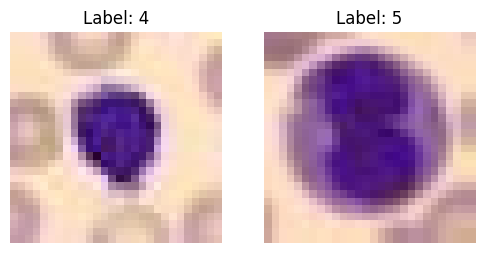

In [31]:
dls.show_batch(max_n=2)

In [32]:
from bonsai.data import BioDataLoaders, get_parent, BioImage, BioLabel, BioOneHot
from bonsai.metrics import ROCAUCMetric, AveragePrecisionMetric, AccuracyMetric
from bonsai.losses import CrossEntropyLoss
from bonsai.backend import set_backend
from torch import nn, flatten as torchflatten
from fastai.metrics import accuracy

In [33]:
# Small CNN for the integration test
class TestCNN(nn.Module):
    def __init__(self, n_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )

        self.classifier = nn.Linear(32, n_classes)

    def forward(self, x):
        x = self.features(x)
        x = torchflatten(x, 1)
        return self.classifier(x)


model = TestCNN(n_classes=8)

In [34]:
monai_biotrainer = BioTrainer(model,
                              dls,
                              optimizer=Adam,
                              validate=True,
                              valid_every=1,
                              device="cuda",
                              loss=CrossEntropyLoss,
                              metrics=ROCAUCMetric,
                              epochs=5,
                              backend_kwargs={
                                  "epoch_length": 5,
                                  "logger": {"figsize": (5, 4)}
                              }
                              )

epoch,iteration,loss,val_loss,ROCAUC,val_ROCAUC,Train time,Val time,Epoch time
1/5,5/5,2.061679 ± 0.014098,2.048945,0.444958,0.578341,0.414 s,1.564 s,2.234 s
2/5,5/5,2.030404 ± 0.023283,2.035188,0.474143,0.596501,0.296 s,1.071 s,1.475 s
3/5,5/5,2.068359 ± 0.048590,2.022900,0.521761,0.591937,0.341 s,1.098 s,1.539 s
4/5,5/5,2.006887 ± 0.029056,2.012320,0.504687,0.593825,0.318 s,1.328 s,1.753 s
5/5,5/5,1.996969 ± 0.066540,2.003413,0.571711,0.591755,0.325 s,2.087 s,2.412 s
Summary,Best epoch: 2,2.030404 ± 0.023283,2.035188,0.474143,0.596501,1.693 s,6.285 s,8.660 s


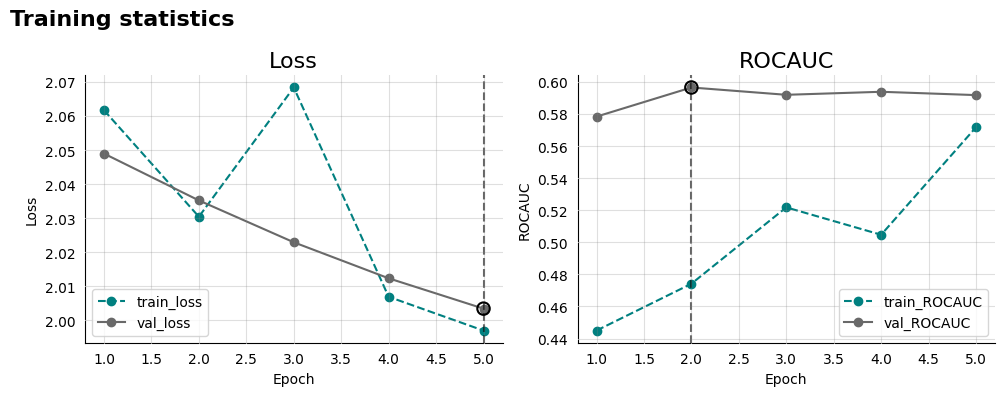

In [35]:
monai_biotrainer.fit()

/home/bm/miniforge3/envs/bonsai-latest-ignite/lib/python3.11/site-packages/monai/metrics/rocauc.py:83: UserWarning: y values can not be all 0.0, skip AUC computation and return `Nan`.
  warnings.warn(f"y values can not be all {y_unique.item()}, skip AUC computation and return `Nan`.")


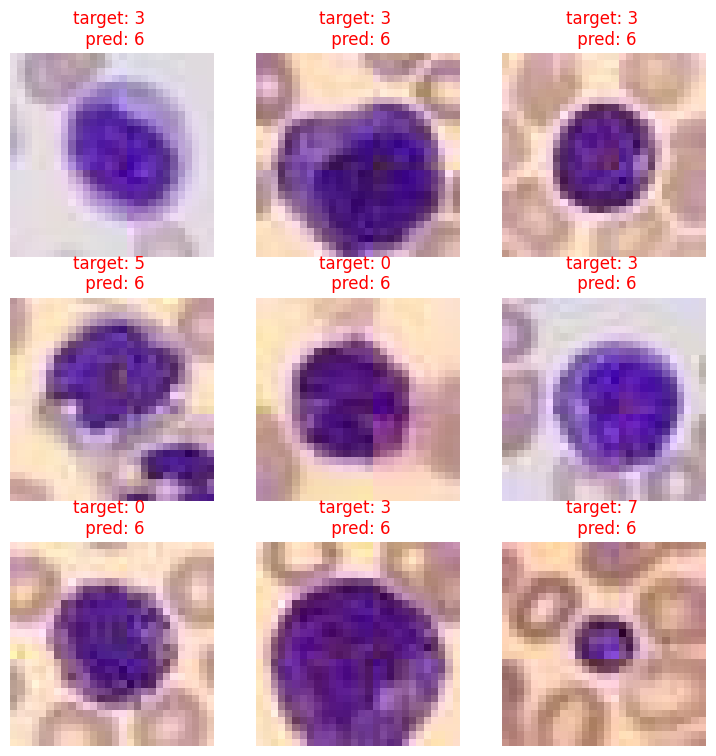

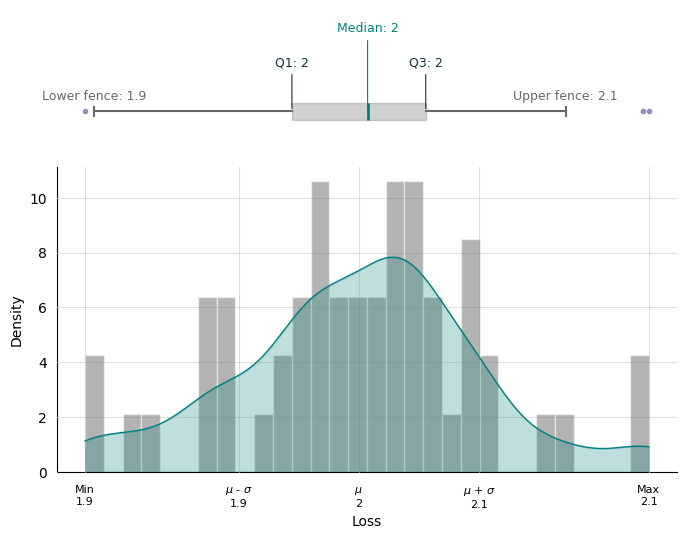

,Value
Loss,
Mean,2.003572
Median,2.007668
Standard Deviation,0.055882
Min,1.876354
Max,2.138337
Q1,1.972484
Q3,2.034700


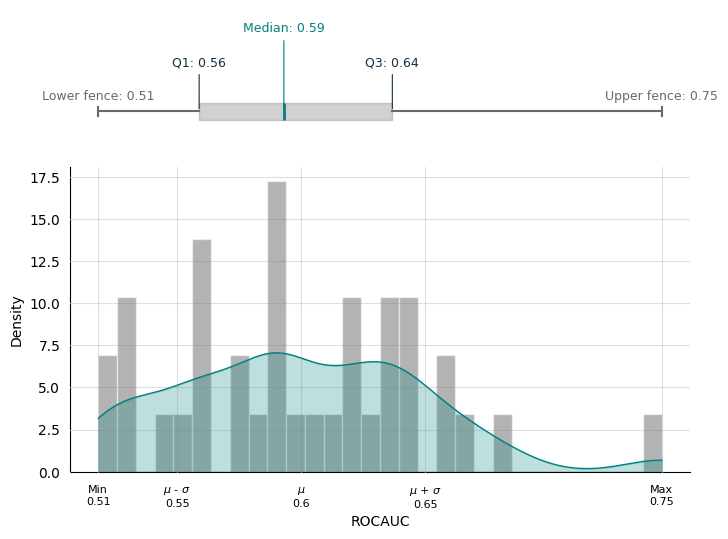

,Value
ROCAUC,
Mean,0.599470
Median,0.592236
Standard Deviation,0.051796
Min,0.514744
Max,0.749942
Q1,0.556862
Q3,0.637477


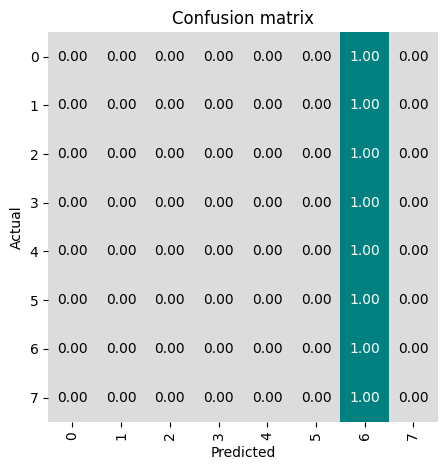

Actual,Predicted,Count
1,6,312
3,6,290
7,6,235
2,6,155
5,6,143


Class / summary,precision,recall,f1-score,support
0,0.000,0.000,0.000,122
1,0.000,0.000,0.000,312
2,0.000,0.000,0.000,155
3,0.000,0.000,0.000,290
4,0.000,0.000,0.000,122
5,0.000,0.000,0.000,143
6,0.195,1.000,0.326,333
7,0.000,0.000,0.000,235
accuracy,—,—,0.195,"1,712"
macro avg,0.024,0.125,0.041,"1,712"


In [36]:
val_res = monai_biotrainer.evaluate(classification_report=True)

In [37]:
#| hide
import nbdev;

nbdev.nbdev_export()